# Portable current-starved VCO generator: one notebook, one switch, two open PDKs
**IEEE SSCS Code-a-Chip, ISSCC 2027 submission** · [Open in Colab](https://colab.research.google.com/github/Gunethra/sscs-ose-code-a-chip.github.io/blob/main/ISSCC27/submitted_notebooks/portable_vco_generator/portable_vco_generator.ipynb) *(set your fork's user name)*

| Name | Affiliation | Role |
|---|---|---|
| `<Your Name>` | `<Your Affiliation>` | Sole author and designated representative |

License: Apache-2.0 (see `LICENSE`).

## Abstract
A single Python generator takes a PDK name and a frequency target and produces a **current-starved ring VCO**: it sizes the circuit, simulates it with ngspice, characterises it, builds the layout with gLayout, checks DRC and LVS with Magic and netgen, extracts parasitics and re-simulates. Switching `sky130` for `gf180mcu` is a **one-word change**. The notebook reports exactly *what had to differ* between the two PDKs and what did not, and it ends with a verification cell that re-runs the flow and compares against stored golden values.

**What you will find here**
1. Environment: pinned tools and PDK versions, installed from this notebook.
2. The generator and the single place where PDK-specific knowledge lives.
3. Sizing to a target frequency and a standard characterisation suite (tuning curve, Kvco, power, corners, temperature, supply).
4. An honest look at supply sensitivity: it traced to a bias-circuit flaw, not to the PDK.
5. A Monte Carlo study of local mismatch.
6. Layout of a 5-stage ring + bias branch, DRC clean and LVS matched on both PDKs.
7. Post-layout (parasitic C) simulation versus schematic.
8. A portability table and lessons learned.
9. A verification cell (`verify.py`) for reproducibility.

## 0. Environment
Two environments are created inside the project folder, nothing is installed system-wide:

| Env | Purpose | Spec |
|---|---|---|
| `.env` | ngspice, Magic, netgen, sky130A + gf180mcuC PDKs, Python analysis stack | `environment.yml` + `environment-eda.txt` |
| `.env-layout` | gLayout 0.2.0 / gdsfactory 7.7 (pins `numpy<=1.24`, so it cannot share `.env`) | `requirements-layout.txt` |

The install is **split in two steps** because a single solve fails on litex-hub's old Qt/KLayout pins. The PDKs are large (the sky130A package is a 1.3 GB download that expands to about 9 GB), so the first install on a fresh machine takes several minutes.

Flags: `RUN_LAYOUT` regenerates the layout from scratch (slow, ~10 min per PDK); `RUN_POST` re-extracts and re-simulates post-layout. By default the notebook re-runs sizing, characterisation and the supply trade-off, and shows the committed *layout*, *post-layout* and *Monte Carlo* results (`RUN_MC`, `RUN_POST`, `RUN_LAYOUT` recompute them). On a free Colab CPU runtime the default run takes roughly 30–40 minutes including the install.

In [1]:
import os, sys, shutil, subprocess, pathlib, json, platform, datetime

IN_COLAB   = "google.colab" in sys.modules
REPO_URL   = "https://github.com/<your-github-user>/sscs-ose-code-a-chip.github.io"   # TODO set your fork (used on Colab only)
PROJECT    = "ISSCC27/submitted_notebooks/portable_vco_generator"
RUN_LAYOUT = False   # True: rebuild layout + DRC/LVS from scratch
RUN_POST   = False   # True: re-extract the committed GDS and re-run the post-layout sweep
RUN_MC     = False   # True: recompute the 100-sample Monte Carlo + sweep (minutes locally, hours on a free 2-vCPU Colab VM)
RUN_VERIFY_FULL = False   # True: verify.py re-simulates everything again (same cost as sections 4-6); False: it checks this notebook's fresh results

def sh(cmd, cwd=None, check=True, env=None, timeout=None):
    print("$", cmd if len(cmd) < 160 else cmd[:157] + "...")
    r = subprocess.run(cmd, shell=True, cwd=cwd, env=env, executable="/bin/bash", text=True, timeout=timeout,
                       stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    if r.stdout.strip(): print(r.stdout[-1500:])
    if check and r.returncode: raise RuntimeError(f"command failed ({r.returncode})")
    return r

# --- locate (or fetch) the project folder ------------------------------------------------------------
here = pathlib.Path.cwd()
ROOT = next((p for p in [here, *here.parents] if (p / "vco_generator").is_dir()), None)
if ROOT is None:
    assert IN_COLAB, "run this notebook from inside the project folder"
    sh(f"git clone --depth 1 {REPO_URL} /content/repo")
    ROOT = pathlib.Path("/content/repo") / PROJECT
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
ENV, LAYENV = ROOT / ".env", ROOT / ".env-layout"
MM = ROOT / ".tools" / "bin" / "micromamba"
os.environ["MAMBA_ROOT_PREFIX"] = str(ROOT / ".tools" / "root")

# --- toolchain: use what is on PATH, else install into the project folder ------------------------------
def tools_ok(): return all(shutil.which(t) for t in ("ngspice", "magic", "netgen")) and pathlib.Path(os.environ.get("PDK_ROOT", "/nonexistent")).is_dir()

if not tools_ok():
    os.environ["PATH"] = f"{ENV}/bin:" + os.environ["PATH"]; os.environ["PDK_ROOT"] = str(ENV / "share" / "pdk")
if not tools_ok():
    if not MM.exists():
        MM.parent.mkdir(parents=True, exist_ok=True)
        sh(f"curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj -C {MM.parent.parent} bin/micromamba")
    sh(f"{MM} create -y -p {ENV} -f environment.yml")                                     # step 1: conda-forge
    sh(f"{MM} install -y -p {ENV} -c litex-hub -c conda-forge $(grep -v '^#' environment-eda.txt)")   # step 2: EDA + PDKs
assert tools_ok(), "toolchain missing"

if (RUN_LAYOUT or not (ROOT / "layout" / "out" / "sky130_ring5.gds").exists()) and not LAYENV.exists():
    sh(f"{MM} create -y -p {LAYENV} -c conda-forge python=3.11 pip")
    sh(f"{LAYENV}/bin/pip install -q -r requirements-layout.txt")
print("project:", ROOT)

project: /home/fai01_xilinx/Documents/sscs-ose-code-a-chip.github.io/ISSCC27/submitted_notebooks/portable_vco_generator


In [2]:
def first_line(cmd, key=None):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True, stdin=subprocess.DEVNULL, timeout=30, executable="/bin/bash")
    lines = [l for l in (r.stdout + r.stderr).splitlines() if l.strip() and (key is None or key in l)]
    return lines[0].strip() if lines else "?"

import numpy, scipy, matplotlib, pandas
pdk_root = pathlib.Path(os.environ["PDK_ROOT"])
versions = {
    "python": platform.python_version(), "numpy": numpy.__version__, "pandas": pandas.__version__, "matplotlib": matplotlib.__version__,
    "ngspice": first_line("ngspice --version", "ngspice-"),
    "magic": first_line("magic --version"),
    "netgen": first_line("netgen -batch quit", "Netgen"),
    "sky130A": "present" if (pdk_root / "sky130A").is_dir() else "MISSING",
    "gf180mcuC": "present" if (pdk_root / "gf180mcuC").is_dir() else "MISSING",
}
for k, v in versions.items(): print(f"{k:11s} {v}")
print("\nPinned (environment-eda.txt):"); print("\n".join(l for l in open("environment-eda.txt").read().splitlines() if l and not l.startswith("#")))

python      3.11.17
numpy       2.4.6
pandas      3.0.6
matplotlib  3.11.2
ngspice     ** ngspice-41 : Circuit level simulation program
magic       8.3.464
netgen      Netgen 1.5.272 compiled on Tue Mar  5 23:16:53 UTC 2024
sky130A     present
gf180mcuC   present

Pinned (environment-eda.txt):
open_pdks.sky130a=1.0.471_0_g97d0844
open_pdks.gf180mcuc=1.0.471_1_gd8bfd6f
magic=8.3.464_0_gcb73ebf
netgen=1.5.272_0_g178af5f


## 1. The circuit
A ring of an odd number *N* of inverters oscillates with period ≈ 2·*N*·*t*<sub>d</sub>. Each inverter is **current-starved**: a header PMOS and a footer NMOS limit its current, so *t*<sub>d</sub> ≈ *C*·*V*/*I* and the frequency follows the control current:

$$ f \;\approx\; \frac{I_\mathrm{ctrl}}{2\,N\,C_\mathrm{stage}\,V_\mathrm{swing}} $$

`Vctrl` drives every footer NMOS directly and also a bias branch (NMOS + diode-connected PMOS) whose gate voltage `VB` biases every header PMOS as a current mirror. Switching the starving off (`starve=False`) leaves a plain ring oscillator, so both circuits come from one generator.

```
  one stage (series stack, supply to ground)             bias branch (shared by all stages)

  VDD ─────────────┐                                     VDD ───────┐
            header PMOS   gate = VB                                  │
                   │                                      diode-connected PMOS  (gate = drain = VB)
            inverter PMOS ─┐                                         │
                   ├──────── VOUT   (inverter gates = VIN)           ├──── VB
            inverter NMOS ─┘                                         │
                   │                                      bias NMOS  gate = VCTRL
            footer NMOS   gate = VCTRL                               │
  VSS ─────────────┘                                     VSS ───────┘
```
The five stages are connected in a ring (VOUT of one stage is VIN of the next). Every footer NMOS shares the bias NMOS's gate, and every header PMOS mirrors the diode-connected PMOS, so each stage's current follows the bias branch.
The first-order formula is only the starting point for sizing: the simulation is the authority.

## 2. The generator and the one place that knows about PDKs
Everything PDK-specific lives in `vco_generator/pdk.py`: device names, supply, minimum dimensions, corner names, how the library is included, and how lengths are printed. The table below is generated from that file.

In [3]:
import pandas as pd
from IPython.display import display, Image
from vco_generator import PDKS, get_pdk, VcoSpec, build_netlist

rows = {k: {"VDD [V]": p.vdd, "Lmin [um]": p.lmin_um, "Wmin usable in layout [um]": p.wmin_um,
            "NMOS": p.nmos, "PMOS": p.pmos, "corner sections": "/".join(p.corners.values()),
            "W/L printed as": p.len_fmt, "library include": p.includes[-1].split("}/")[-1][:48]} for k, p in PDKS.items()}
display(pd.DataFrame(rows))

,sky130,gf180mcu
VDD [V],1.8,3.3
Lmin [um],0.15,0.28
Wmin usable in layout [um],0.42,0.46
NMOS,sky130_fd_pr__nfet_01v8,nfet_03v3
PMOS,sky130_fd_pr__pfet_01v8,pfet_03v3
corner sections,tt/ss/ff/sf/fs,typical/ss/ff/sf/fs
W/L printed as,{x:.4g},{x:.4g}u
library include,sky130A/libs.tech/ngspice/sky130.lib.spice {corn,gf180mcuC/libs.tech/ngspice/sm141064.ngspice {co


Same circuit, two PDKs. The unified diff below shows **every line of the generated netlist that differs** between sky130 and gf180mcu: the library includes, the supply, the device model names and the length/width formatting. The topology (every connection) is identical.

In [4]:
import difflib
spec0 = VcoSpec()
a = build_netlist(get_pdk("sky130"),   spec0, vctrl=1.0).splitlines()
b = build_netlist(get_pdk("gf180mcu"), spec0, vctrl=1.0).splitlines()
diff = [l for l in difflib.unified_diff(a, b, "sky130", "gf180mcu", lineterm="", n=0) if not l.startswith(("@@", "---", "+++"))]
print(f"{len(a)} netlist lines, {sum(l.startswith('-') for l in diff)} differ:\n"); print("\n".join(diff[:24]), "\n...")

33 netlist lines, 25 differ:

-* current-starved ring VCO  pdk=sky130 corner=tt N=5 vctrl=1
-.lib /home/fai01_xilinx/Documents/sscs-ose-code-a-chip.github.io/ISSCC27/submitted_notebooks/portable_vco_generator/.env/share/pdk/sky130A/libs.tech/ngspice/sky130.lib.spice tt
+* current-starved ring VCO  pdk=gf180mcu corner=tt N=5 vctrl=1
+.include /home/fai01_xilinx/Documents/sscs-ose-code-a-chip.github.io/ISSCC27/submitted_notebooks/portable_vco_generator/.env/share/pdk/gf180mcuC/libs.tech/ngspice/design.ngspice
+.lib /home/fai01_xilinx/Documents/sscs-ose-code-a-chip.github.io/ISSCC27/submitted_notebooks/portable_vco_generator/.env/share/pdk/gf180mcuC/libs.tech/ngspice/sm141064.ngspice typical
-Vdd vdd 0 1.8
+Vdd vdd 0 3.3
-XMbn vb vctrl 0 0 sky130_fd_pr__nfet_01v8 L=0.3 W=1
-XMbp vb vb vdd vdd sky130_fd_pr__pfet_01v8 L=0.3 W=2
-XMhp0 p0 vb vdd vdd sky130_fd_pr__pfet_01v8 L=0.3 W=2
-XMfn0 s0 vctrl 0 0 sky130_fd_pr__nfet_01v8 L=0.3 W=1
-XMp0 n1 n0 p0 vdd sky130_fd_pr__pfet_01v8 L=0.15 W=2
-X

## 3. Sanity: the plain ring oscillator
With starving switched off the circuit is a free-running ring whose speed is set by the PDK alone. This is a quick check that both PDKs are wired up correctly before anything is sized.

In [5]:
from dataclasses import replace
from vco_generator.simulate import run_point
rows = []
for name in ("sky130", "gf180mcu"):
    p = get_pdk(name); pt = run_point(p, replace(spec0, starve=False), vctrl=p.vdd)
    rows.append({"pdk": name, "VDD [V]": p.vdd, "f [MHz]": round(pt.f_hz/1e6), "stage delay [ps]": round(1e12/(2*5*pt.f_hz), 1),
                 "power [uW]": round(pt.p_w*1e6, 1), "energy/cycle [fJ]": round(pt.e_cycle_j*1e15)})
display(pd.DataFrame(rows).set_index("pdk"))

,VDD [V],f [MHz],stage delay [ps],power [uW],energy/cycle [fJ]
pdk,,,,,
sky130,1.8,4761,21.0,419.0,88
gf180mcu,3.3,2569,38.9,1215.5,473


## 4. Sizing to a target and characterising
`size_for_frequency` bisects the starving-device width (log scale) until the oscillator runs at the target frequency at mid-range `Vctrl`. If the PDK's **minimum usable width** is reached before the target, it lengthens the starving devices instead. `characterize` then runs the same suite for every PDK:

* tuning curve (12 points), tuning ratio, Kvco at mid-range
* power and energy per cycle
* five process corners at mid-range `Vctrl`
* temperature (−40, 27, 125 °C) and supply (±10 %) sensitivity

In [6]:
from vco_generator.analysis import size_for_frequency, characterize, save, vctrl_mid, supply_vs_starve_pn
F_TARGET = 400e6
results, specs = {}, {}
for name in ("sky130", "gf180mcu"):
    pdk = get_pdk(name)
    specs[name] = size_for_frequency(pdk, VcoSpec(), F_TARGET)
    r = characterize(pdk, specs[name]); r["starve_pn"] = specs[name].starve_pn or pdk.pn_ratio
    save(r, ROOT / "results" / f"{name}.json"); results[name] = r

tbl = {n: {"starving W [um]": r["ws_um"], "starving L [x Lmin]": r["l_starve_factor"], "f at mid Vctrl [MHz]": round(r["f_mid_hz"]/1e6, 1),
           "Kvco [MHz/V]": round(r["kvco_mid_hz_per_v"]/1e6), "tuning ratio": round(r["tuning_ratio"]), "power [uW]": round(r["p_mid_w"]*1e6),
           "energy/cycle [fJ]": round(r["e_cycle_mid_j"]*1e15), "corner spread [%]": round(r["corner_spread_pct"]),
           "temp coeff [ppm/C]": round(r["temp_coeff_ppm_per_c"]), "supply sens [%/V]": round(r["supply_sens_pct_per_v"], 1)} for n, r in results.items()}
display(pd.DataFrame(tbl))

,sky130,gf180mcu
starving W [um],0.622,0.678
starving L [x Lmin],8.000,4.000
f at mid Vctrl [MHz],402.000,399.500
Kvco [MHz/V],682.000,380.000
tuning ratio,63.000,70.000
power [uW],60.000,403.000
energy/cycle [fJ],149.000,1008.000
corner spread [%],74.000,41.000
temp coeff [ppm/C],-1957.000,-3060.000
supply sens [%/V],55.300,-14.900


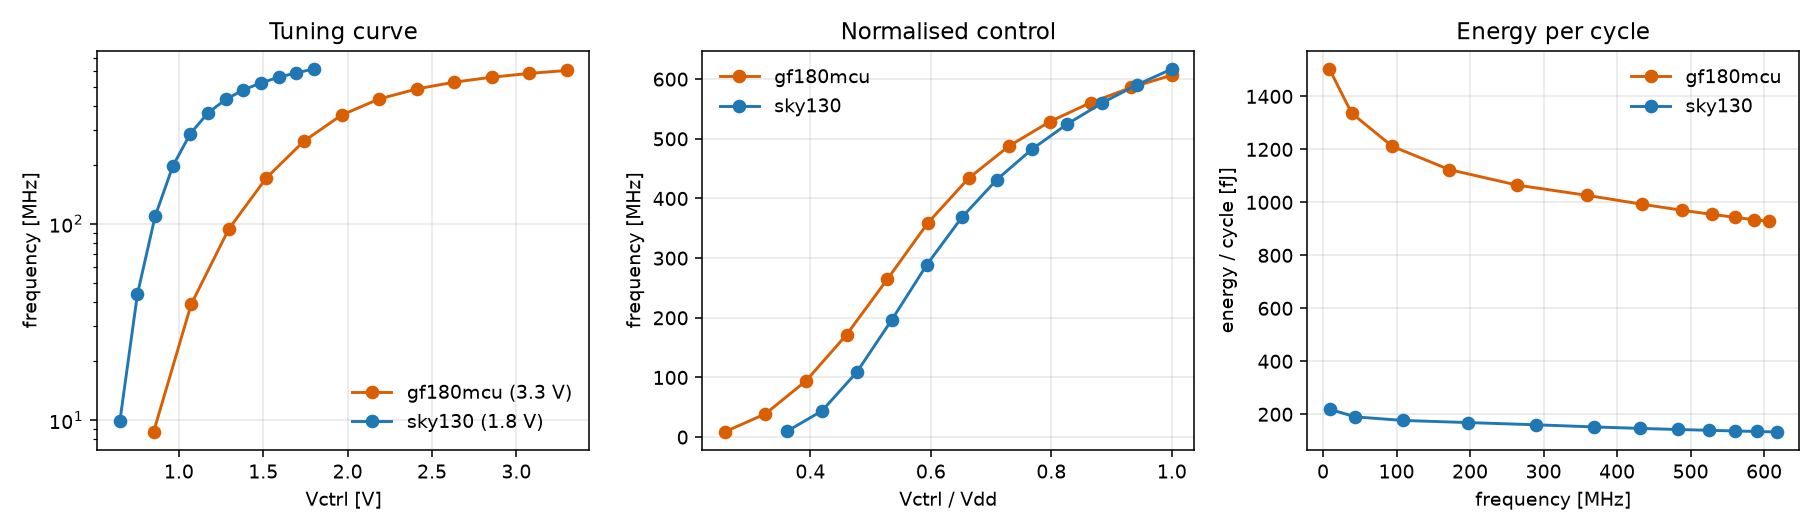

In [7]:
from vco_generator.plots import compare
display(Image(compare(str(ROOT / "results"), str(ROOT / "results" / "comparison.png"))))

**Reading the plots.** In absolute `Vctrl` (left) the PDKs are far apart because of their different supplies. When `Vctrl` is normalised to `Vdd` (middle) the two tuning curves nearly coincide: the *topology* ports cleanly. What does not port is the **cost**: energy per cycle (right) is about 7× higher on gf180mcu, mostly because of its 3.3 V supply.

## 5. Supply sensitivity: a bias-circuit flaw, not a PDK property
At fixed `Vctrl` the sky130 ring's frequency *rises* strongly with the supply while gf180's *falls*. Looking at the bias branch alone showed why: on sky130 the bias NMOS had only 0.15–0.33 V across it while its gate sat near 1.2 V, so it ran in **triode** and acted as a resistor, not a current source, and its current followed `Vdd`. gf180's current barely changed with the supply (about ±8 % for ±10 % on Vdd).

A wider starving PMOS raises the bias node and keeps the NMOS out of triode, but it also speeds the oscillator up, so holding the 400 MHz target forced the sky130 starving devices to about 64× the minimum length in an earlier trial (recorded in `DEVLOG.md`). A redesigned bias (for example cascoded) would likely fix this properly but was not attempted. The simple bias was kept and the trade-off is documented here:

In [8]:
rows = []
for name in ("sky130", "gf180mcu"):
    pdk = get_pdk(name)
    base = replace(VcoSpec(), ws_um=results[name]["ws_um"], l_starve_factor=results[name]["l_starve_factor"])
    for r in supply_vs_starve_pn(pdk, base):
        rows.append({"pdk": name, "starving PMOS/NMOS width": r["starve_pn"], "f at mid Vctrl [MHz]": round(r["f_mid_hz"]/1e6),
                     "supply sensitivity [%/V]": round(r["supply_sens_pct_per_v"], 1)})
display(pd.DataFrame(rows))

,pdk,starving PMOS/NMOS width,f at mid Vctrl [MHz],supply sensitivity [%/V]
0,sky130,2.0,402,55.3
1,sky130,4.0,560,21.5
2,sky130,8.0,717,12.1
3,gf180mcu,2.5,399,-14.9
4,gf180mcu,5.0,452,-31.9
5,gf180mcu,10.0,523,-39.6


The rows are *not* iso-frequency (the width is not re-sized as the ratio changes): this is a trade-off sketch. For an ideal current source with a fixed voltage swing the frequency would scale as 1/*V*<sub>dd</sub>, i.e. about −56 %/V on sky130 and −30 %/V on gf180. The simulated numbers show that a wider PMOS moves **gf180 further negative** (past −30 %/V, so its current also falls with the supply, not analysed here) and **sky130 towards zero** (+12 %/V at the widest PMOS, also not root-caused). Neither sign nor size is a PDK property: both come from this simple bias circuit.

## 6. Monte Carlo: local mismatch
Same sized design, **100 seeded ngspice runs** with each PDK's *local mismatch* models switched on (sky130: the `tt_mm` library section; gf180mcu: `sw_stat_mismatch=1`, which draws per-device `Vth` and mobility offsets from area-scaled Gaussians). Seeds are set with `.options seed=N`, so every number below is reproducible. Global process variation is not included here (the corner and temperature results above cover the systematic spread), and the bias branch's mismatch is part of the total, not separated.

In [9]:
import numpy as np
from vco_generator.montecarlo import monte_carlo
mc, mcv = {}, {}
for name in ("sky130", "gf180mcu"):
    if RUN_MC:
        pdk = get_pdk(name); sp = replace(VcoSpec(), ws_um=results[name]["ws_um"], l_starve_factor=results[name]["l_starve_factor"], starve_pn=results[name]["starve_pn"])
        mc[name] = monte_carlo(pdk, sp, vctrl_mid(pdk), n=100)
        json.dump(mc[name], open(ROOT / "results" / f"mc_{name}.json", "w"), indent=1)
        sweep_mc = {round(float(v), 2): monte_carlo(pdk, sp, float(v), n=40) for v in np.linspace(pdk.vctrl_lo + 0.1, pdk.vdd, 5)}
        mcv[name] = {k: {"sigma_pct": m["sigma_pct"], "f_mean_hz": m["f_mean_hz"], "p_sigma_pct": m["p_sigma_pct"]} for k, m in sweep_mc.items()}
        json.dump(mcv[name], open(ROOT / "results" / f"mc_vs_vctrl_{name}.json", "w"), indent=1)
    else:   # committed results of the same seeded run (set RUN_MC = True to recompute)
        mc[name] = json.load(open(ROOT / "results" / f"mc_{name}.json"))
        mcv[name] = {float(k): v for k, v in json.load(open(ROOT / "results" / f"mc_vs_vctrl_{name}.json")).items()}

display(pd.DataFrame({n: {"samples": m["n"], "nominal f [MHz]": round(m["f_nominal_hz"]/1e6, 1), "mean f [MHz]": round(m["f_mean_hz"]/1e6, 1),
                          "sigma(f)/f [%]": round(m["sigma_pct"], 2), "mean shift [%]": round(m["mean_shift_pct"], 2),
                          "min..max [MHz]": f'{m["f_min_hz"]/1e6:.0f}..{m["f_max_hz"]/1e6:.0f}', "within +-5 %": f'{100*m["frac_within_5pct"]:.0f} %',
                          "sigma(power)/P [%]": round(m["p_sigma_pct"], 2)} for n, m in mc.items()}))

,sky130,gf180mcu
samples,100,100
nominal f [MHz],402.0,399.5
mean f [MHz],401.6,399.6
sigma(f)/f [%],0.91,0.39
mean shift [%],-0.08,0.03
min..max [MHz],393..411,395..404
within +-5 %,100 %,100 %
sigma(power)/P [%],0.59,0.38


In [10]:
from matplotlib.figure import Figure
fig = Figure(figsize=(11, 3.6)); ax = fig.subplots(1, 3)
for n, c in (("sky130", "#1f77b4"), ("gf180mcu", "#d95f02")):
    ax[0 if n == "sky130" else 1].hist(100 * (np.array(mc[n]["f_hz"]) / mc[n]["f_nominal_hz"] - 1), bins=14, color=c, alpha=.8)
    ax[0 if n == "sky130" else 1].set(title=f"{n}: {mc[n]['n']} samples, sigma = {mc[n]['sigma_pct']:.2f} %", xlabel="frequency deviation from nominal [%]", ylabel="count")
    v = sorted(mcv[n]); ax[2].semilogy([x / get_pdk(n).vdd for x in v], [mcv[n][x]["sigma_pct"] for x in v], "o-", color=c, label=n)
ax[2].set(title="mismatch sigma vs control voltage", xlabel="Vctrl / Vdd", ylabel="sigma(f)/f [%]"); ax[2].legend(frameon=False)
for a_ in ax: a_.grid(alpha=.3)
fig.tight_layout(); display(fig)

<Figure size 1100x360 with 3 Axes>

**Reading it.** At mid-range control the ring is tolerant of mismatch: every one of the 100 samples stays within ±5 % of nominal on both PDKs (a 5-stage ring plausibly averages some of the stage-to-stage differences; that was not tested separately). The spread **grows several-fold at low `Vctrl`** (right plot), most likely because the starving devices approach weak inversion, where current depends exponentially on a threshold offset (not verified here). The sky130 design is about 2× more sensitive than gf180mcu at mid-range. The starving devices have similar area in both PDKs, so the difference points to the PDKs' mismatch coefficients and bias headroom; this was not investigated further.

## 7. Layout with gLayout, DRC and LVS
Layout is generated by [gLayout](https://github.com/ReaLLMASIC/gLayout) (`layout/cells.py`, `layout/ring.py`): a stage cell (footer NMOS, inverter NMOS, inverter PMOS, header PMOS, with routing and pin labels), a bias cell, and a ring that places the bias branch and five stages side by side. Supplies run on met4 rails, `VCTRL`/`VB` on met4 rails with met5 drops that cross the supply rails, stage-to-stage links on met4, and the wrap-around on met5.

Sizes are read from `results/<pdk>.json`, so the layout is the *simulated, sized* design. Checks: **Magic DRC** and **netgen LVS** against a schematic netlist generated from the same cells.

Things worth knowing, all found the hard way and listed in `DEVLOG.md`:
* gLayout's gf180 setup expects the `gf180mcuD` variant. With `gf180mcuC` installed, Magic silently loaded no tech and printed "DRC passed" (**a false pass**); the explicit `gf180mcuC` rule files are passed instead.
* gf180's thick top metal needs width ≥ 0.44 µm / spacing ≥ 0.46 µm, but gLayout's rule table says 0.28.
* gLayout cannot contact a device narrower than about 0.46 µm on gf180 although the device minimum is 0.22 µm, so the generator's `wmin_um` for gf180 is 0.46.
* gLayout's LVS wrapper prints "Errors found" whenever the report has more than 3 lines; the real status is netgen's `Final result:` line, which is what is reported below.

In [11]:
LAYOUT = ROOT / "layout"
if RUN_LAYOUT:
    for name in ("sky130", "gf180mcu"):
        env = dict(os.environ, VCO_ROOT=str(ROOT), PYTHONPATH=str(LAYOUT))
        (LAYOUT / "out" / "work").mkdir(parents=True, exist_ok=True)
        sh(f"{LAYENV}/bin/python {LAYOUT}/check_ring.py {name} 5", cwd=LAYOUT / "out" / "work", env=env, timeout=3000)
        sh(f"{LAYENV}/bin/python {LAYOUT}/render.py {LAYOUT}/out/{name}_ring5.gds {LAYOUT}/out/{name}_ring5.png", check=False)

checks = {n: json.load(open(LAYOUT / "out" / f"{n}_ring5_checks.json")) for n in ("sky130", "gf180mcu")}
display(pd.DataFrame({n: {"stages": c["stages"], "bbox [um]": f'{c["bbox_um"][2]-c["bbox_um"][0]:.0f} x {c["bbox_um"][3]-c["bbox_um"][1]:.0f}',
                          "DRC": "clean" if c["drc_clean"] else f'{len(c["drc_violations"])} violations', "LVS": c["lvs"]} for n, c in checks.items()}))

,sky130,gf180mcu
stages,5,5
bbox [um],105 x 40,113 x 44
DRC,clean,clean
LVS,Circuits match uniquely.,Circuits match uniquely.


sky130 - 5-stage ring + bias branch


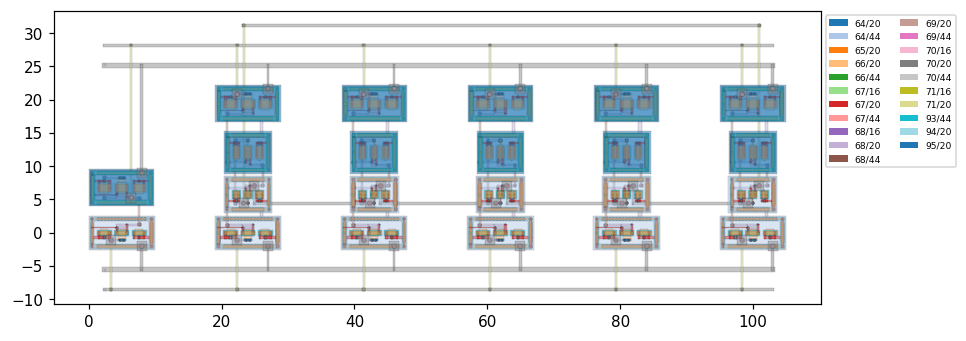

gf180mcu - 5-stage ring + bias branch


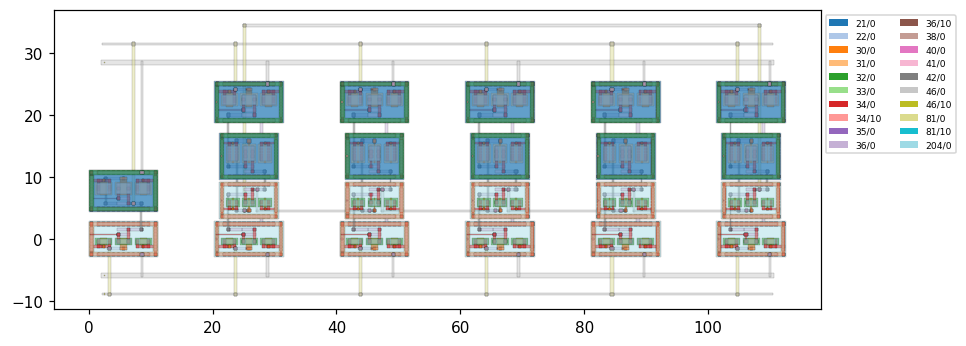

In [12]:
for n in ("sky130", "gf180mcu"):
    print(n, "- 5-stage ring + bias branch")
    display(Image(str(LAYOUT / "out" / f"{n}_ring5.png"), width=900))

## 8. Post-layout simulation
Magic extracts the parasitic **capacitance** of the layout (flattened, `ext2spice scale off` for gf180) and ngspice re-runs the same `Vctrl` sweep on the extracted netlist. **Wire resistance is not extracted**, and the extracted netlist includes the dummy devices.

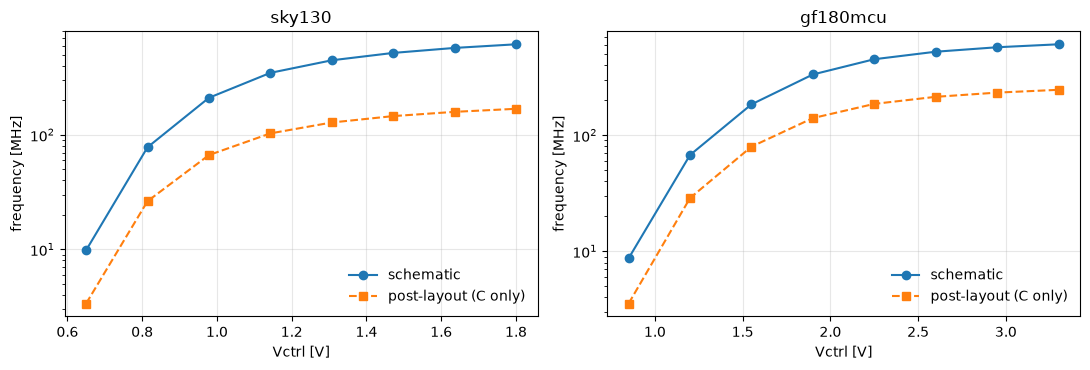

sky130,0.65,0.81,0.98,1.14,1.31,1.47,1.64,1.80
schematic [MHz],9.8,77.9,210.5,347.5,447.3,518.8,573.6,617.0
post-layout [MHz],3.4,26.3,66.6,102.9,128.1,145.7,158.7,168.7
change,-66 %,-66 %,-68 %,-70 %,-71 %,-72 %,-72 %,-73 %


gf180mcu,0.85,1.20,1.55,1.90,2.25,2.60,2.95,3.30
schematic [MHz],8.7,67.5,184.3,333.4,451.2,523.6,572.2,606.8
post-layout [MHz],3.5,28.7,79.6,140.3,186.0,214.0,232.7,245.9
change,-59 %,-57 %,-57 %,-58 %,-59 %,-59 %,-59 %,-59 %


In [13]:
import numpy as np, matplotlib.pyplot as plt
if RUN_POST:
    for name in ("sky130", "gf180mcu"):
        sh(f"python -m vco_generator.compare_post --pdk {name}", cwd=ROOT, timeout=3000)
post = {n: json.load(open(ROOT / "results" / "extra" / f"post_layout_{n}.json")) for n in ("sky130", "gf180mcu")}

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a_, (n, d) in zip(ax, post.items()):
    v = np.array(d["vctrl"]); s = np.array(d["schematic"]["f_hz"]) / 1e6; p = np.array(d["post_layout"]["f_hz"]) / 1e6
    a_.semilogy(v, s, "o-", label="schematic"); a_.semilogy(v, p, "s--", label="post-layout (C only)")
    a_.set(title=n, xlabel="Vctrl [V]", ylabel="frequency [MHz]"); a_.grid(alpha=.3); a_.legend(frameon=False)
fig.tight_layout(); display(fig); plt.close(fig)
for n, d in post.items():
    display(pd.DataFrame({"Vctrl [V]": [round(v, 2) for v in d["vctrl"]], "schematic [MHz]": [round(x/1e6, 1) for x in d["schematic"]["f_hz"]],
                          "post-layout [MHz]": [round(x/1e6, 1) for x in d["post_layout"]["f_hz"]],
                          "change": [f"{100*(p/s-1):+.0f} %" for s, p in zip(d["schematic"]["f_hz"], d["post_layout"]["f_hz"])]}).set_index("Vctrl [V]").rename_axis(n).T)

**The layout slows the oscillator by roughly 57–73 %.** This is large but plausible: the stage devices are tiny, so the roughly 19 µm met4 links between stages and the long wrap-around wire add a few femtofarads to each stage output (about 4 fF on sky130, 10 fF on the probe node), comparable to or larger than the next stage's own gate load. The cell below checks that the effect really comes from the extracted capacitors and not from something else in the extracted netlist: removing the capacitors (same devices, dummies included) brings the frequency back close to the schematic value.

In [14]:
from vco_generator.postlayout import extract, run_point_post
pdk = get_pdk("sky130"); spice = "results/extra/sky130_ring5_pex.spice"
extract("layout/out/sky130_ring5.gds", "RING", pdk, spice)
caps = [l.split() for l in open(spice) if l.startswith("C")]
vm = 1.14
f_nc = run_point_post(pdk, spice, "RING_flat", vm, no_caps=True).f_hz; f_c = run_point_post(pdk, spice, "RING_flat", vm).f_hz
f_s = run_point(pdk, replace(VcoSpec(), ws_um=results["sky130"]["ws_um"], l_starve_factor=results["sky130"]["l_starve_factor"], starve_pn=results["sky130"]["starve_pn"]), vm).f_hz
print(f"sky130 @ Vctrl={vm} V:  schematic {f_s/1e6:.0f} MHz | extracted netlist, capacitors removed {f_nc/1e6:.0f} MHz | extracted with {len(caps)} capacitors {f_c/1e6:.0f} MHz")

sky130 @ Vctrl=1.14 V:  schematic 345 MHz | extracted netlist, capacitors removed 292 MHz | extracted with 86 capacitors 102 MHz


## 9. What had to differ between PDKs
| Aspect | sky130 | gf180mcu | Handled in |
|---|---|---|---|
| Supply / device flavour | 1.8 V `nfet_01v8` | 3.3 V `nfet_03v3` | `pdk.py` |
| Minimum length | 0.15 µm | 0.28 µm | `pdk.py`, `L_factor` |
| Library include | one `.lib … tt` line | `.include design.ngspice` + `.lib sm141064.ngspice typical` | `pdk.py` |
| Corner names | tt/ss/ff/sf/fs | typical/ss/ff/sf/fs | `pdk.py` |
| W/L in subckt calls | plain µm numbers | SI suffix (`1.0u`) | `pdk.py` |
| Smallest usable width | 0.42 µm | 0.46 µm (layout contact limit; device min 0.22) | `pdk.py` |
| Starving device length for 400 MHz | 8× Lmin (width floor hit) | 4× Lmin | sizer (automatic) |
| Layout tech used by Magic/netgen | `sky130A` | `gf180mcuC` (gLayout assumes `gf180mcuD`) | `check_*.py` overrides |
| Top-metal width/spacing | 0.3 / 0.4 | 0.44 / 0.46 (rule table wrong) | `layout/cells.py`, `ring.py` |
| n-well spacing between PMOS | 1.27 µm | 1.4 µm | read from the PDK rules |
| Extraction | default | `ext2spice scale off` | `postlayout.py` |
| **Did not change** | topology, generator, sizing algorithm, characterisation suite, layout cells, route recipe |  |  |

**Lessons**
* Put every PDK convention in one file; everything else then ports for free.
* A simulation-only sizer must carry layout-feasibility limits (minimum contactable width), or the layout step fails later.
* A tool that prints "passed" may not have run: confirm the tech file was actually loaded before trusting a clean DRC.
* Parasitics matter more than expected for minimum-size ring oscillators: a schematic-only result overstates speed by roughly 2.3–3.7× here.

## 10. Verification: re-run and compare against the golden values
`verify.py` re-sizes and re-characterises both PDKs and compares **48 metrics** (plus the Monte Carlo statistics with `--mc`) against `golden/*.json` (tolerances 2–10 % depending on the metric; 20 % on the Monte Carlo sigma). With `--post` it also re-extracts the committed GDS and re-checks the post-layout frequencies. Exit code 0 means everything is within tolerance. By default the cell below checks the results this notebook has just computed (seconds); with `RUN_VERIFY_FULL = True` it re-simulates everything independently (same cost as sections 4–6). This is the cell to run on a new machine.

In [15]:
args = [] if RUN_VERIFY_FULL else ["--from-results", "--mc"]    # default: check the results this notebook just produced
r = subprocess.run([sys.executable, "verify.py", *args], cwd=ROOT, capture_output=True, text=True)
print(r.stdout[-1200:], r.stderr[-400:]); print("verify.py exit code:", r.returncode)
assert r.returncode == 0, "metrics deviate from the golden values"

[ ok ] sky130: 24 schematic metrics compared
[ ok ] sky130: 3 Monte Carlo statistics compared
[ ok ] gf180mcu: 24 schematic metrics compared
[ ok ] gf180mcu: 3 Monte Carlo statistics compared

54 values checked, 0 outside tolerance

 
verify.py exit code: 0


## 11. Extending to another PDK
1. Add a `PDK(...)` entry in `vco_generator/pdk.py`: device names, supply, `lmin_um`, smallest usable width, corner map, include lines, number format.
2. `python -m vco_generator --pdk <name> --f-target 400e6` sizes and characterises it.
3. For layout, add the PDK to `get_pdk` in `layout/cells.py`. gLayout also ships an `ihp130` mapped PDK, so IHP SG13G2 is the natural next target; gLayout's LVS is not implemented for it, so it would get layout and DRC only.

## 12. Reproducibility record

In [16]:
print("date      :", datetime.datetime.now().isoformat(timespec="seconds"))
print("host      :", platform.platform())
print("git commit:", first_line("git rev-parse --short HEAD 2>/dev/null || echo not-a-git-checkout"))
print("sim env   :", sum(1 for _ in open("environment.lock.txt")) - 3, "packages pinned in environment.lock.txt")
print("layout env:", sum(1 for _ in open("requirements-layout.txt")) - 1, "packages pinned in requirements-layout.txt")

date      : 2026-10-11T20:29:46
host      : Linux-7.0.0-38-generic-x86_64-with-glibc2.39
git commit: a502a6ba
sim env   : 286 packages pinned in environment.lock.txt
layout env: 81 packages pinned in requirements-layout.txt


## References
* IEEE SSCS Code-a-Chip ISSCC 2027 rules, `README.md` and `FAQ.md` of this repository (install pattern: micromamba + litex-hub).
* Past Code-a-Chip winners studied for structure and approach: OpenFASoC digital LDO generator, GLayout (ISSCC'24, ISSCC'25), current-mirror OTA and current-mode-logic optimisation (ISSCC'25, ISSCC'26), Ron/gm methodology for dynamic amplifiers (VLSI'26), ISSCC'26 EEG amplifier built with gLayout on gf180mcu.
* gLayout 0.2.0 / gdsfactory 7.7.0 (layout generation, `drc_magic`, `lvs_netgen`), Magic 8.3.464, netgen 1.5.272, ngspice 41, open_pdks 1.0.471 (sky130A, gf180mcuC), micromamba 2.9.0.
* Design notes, failures and fixes: `DEVLOG.md`. Install and removal record: `INSTALL_LOG.md`.